# Dengue in Bangladesh — hotspots, burden and deaths (2000 – Oct 2026)

This notebook collects every open dengue dataset for Bangladesh I could find, cleans it, and answers:

1. **How big is the problem over time?** National cases, deaths and case fatality rate (CFR), 2000–2026.
2. **When does it hit?** Monthly seasonality.
3. **Where are the hot zones, and how do they move?** Division-level incidence and relative risk 2020–2026, **maps of 2025 vs 2026**, and district-level maps.
4. **Who dies, and where?** Deaths per million, CFR by division, Dhaka city vs the rest, age and sex.
5. **Does climate matter?** Lagged correlation with temperature and humidity.

All charts are also saved to `figures/` and all tables to `reports/`.

## Data sources

| Dataset | Coverage | Source |
|---|---|---|
| National yearly cases & deaths | 2000 – 21 Oct 2026 | Hossain et al. 2023 ([PMC10334535](https://pmc.ncbi.nlm.nih.gov/articles/PMC10334535/)) for 2000–22; DGHS press releases for 2023–26 |
| Monthly cases, deaths & climate by division | Jan 2020 – Oct 2025 | Mendeley Data [doi:10.17632/cgwjshkx5k.2](https://data.mendeley.com/datasets/cgwjshkx5k) (compiled from DGHS bulletins) |
| **DGHS Dengue Dashboard** snapshot: division & city-corporation totals, weekly division series, monthly national series, age & sex | 2023 – 1 Oct 2026 | [dashboard.dghs.gov.bd](https://dashboard.dghs.gov.bd/pages/heoc_dengue_v1.php), raw JSON captured 1 Oct 2026 by [Ashiq-r-khan/Bangladesh-Dengue-Forecasting-Analysis](https://github.com/Ashiq-r-khan/Bangladesh-Dengue-Forecasting-Analysis) |
| Monthly cases by district (64 districts + Dhaka city hospitals) | Jan 2016 – Feb 2024 | DGHS daily reports, compiled by [Khalidsyfullah/Research-on-Bangladeshi-Dengue-Data](https://github.com/Khalidsyfullah/Research-on-Bangladeshi-Dengue-Data) |
| Population by division and district | Census 2022 | Bangladesh Bureau of Statistics |
| Division & district boundaries | — | [geoBoundaries](https://www.geoboundaries.org) BGD ADM1 (CC0) / ADM2 (BBS/OCHA, CC BY 3.0 IGO) |

In [1]:
import json
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW, EXT, PROC = ROOT / "data/raw", ROOT / "data/external", ROOT / "data/processed"
FIG, REP = ROOT / "figures", ROOT / "reports"
for p in (PROC, FIG, REP):
    p.mkdir(exist_ok=True)

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)

# Colours: validated reference palette (light mode). Sequential = one hue, light -> dark.
SURFACE, INK, INK2, MUTED = "#fcfcfb", "#0b0b0b", "#52514e", "#898781"
GRID, AXIS = "#e1e0d9", "#c3c2b7"
BLUE, ORANGE, CRITICAL = "#2a78d6", "#eb6834", "#d03b3b"
CMAP_BLUE = LinearSegmentedColormap.from_list(
    "seq_blue", ["#f4f8fd", "#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"])
CMAP_ORANGE = LinearSegmentedColormap.from_list(
    "seq_orange", ["#fdf6f2", "#fde3d6", "#f8bfa4", "#f39a72", "#eb6834", "#c64f20", "#8f3713"])
CMAP_RED = LinearSegmentedColormap.from_list(
    "seq_red", ["#fdf4f4", "#f8d4d4", "#f0a9a9", "#e57b7b", "#d03b3b", "#a52a2a", "#6e1a1a"])

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.family": "sans-serif", "font.size": 10, "figure.dpi": 110,
    "text.color": INK, "axes.labelcolor": INK2, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.edgecolor": AXIS, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False, "axes.titleweight": "bold",
    "axes.titlesize": 11, "axes.titlelocation": "left", "axes.axisbelow": True,
})

DIVISIONS = ["Dhaka", "Barishal", "Chattogram", "Khulna", "Rajshahi", "Mymensingh", "Rangpur", "Sylhet"]
MONTHS = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]


def save(fig, name):
    fig.savefig(FIG / name, dpi=160, bbox_inches="tight")
    plt.show()


def note(fig, text, y=-0.02):
    fig.text(0.01, y, text, fontsize=8, color=MUTED)

## 1. Load and clean the data

### 1a. National yearly series and population

In [2]:
national = pd.read_csv(EXT / "national_yearly_2000_2026.csv")
national["cfr_pct"] = national.deaths / national.cases * 100
div_pop = pd.read_csv(EXT / "division_population_2022.csv").set_index("division")["population_2022_adjusted"]
dist_pop = pd.read_csv(EXT / "district_population_2022.csv")
national[["year", "cases", "deaths", "cfr_pct", "period"]].tail(10).round(2)

,year,cases,deaths,cfr_pct,period
17,2017,2769,8,0.29,full year
18,2018,10148,26,0.26,full year
19,2019,101354,179,0.18,full year
20,2020,1405,7,0.50,full year
21,2021,28429,105,0.37,full year
22,2022,62382,281,0.45,full year
23,2023,321179,1705,0.53,full year
24,2024,101214,575,0.57,full year
25,2025,102861,413,0.40,full year
26,2026,116990,364,0.31,1 Jan - 21 Oct 2026 (year to date)


### 1b. Mendeley monthly division data (2020 – Oct 2025)
`Division` and `Year` are merged cells in the spreadsheet, so they are forward-filled. Nov–Dec 2025 rows are empty placeholders.

In [3]:
m = pd.read_excel(RAW / "mendeley/dataset.xlsx")
m.columns = [c.strip().lower() for c in m.columns]
m[["division", "year"]] = m[["division", "year"]].ffill()
m = m.dropna(subset=["month", "infected"])
m["division"] = m.division.str.strip()
m["year"] = m.year.astype(int)
m["month_num"] = m.month.str.strip().str[:3].map({mo: i + 1 for i, mo in enumerate(MONTHS)})
m["date"] = pd.to_datetime(dict(year=m.year, month=m.month_num, day=1))
m["cases"] = m.pop("infected").astype(int)
m["deaths"] = m.pop("death").astype(int)
m["temperature_c"] = m.pop("temperature").astype(str).str.extract(r"([\d.]+)")[0].astype(float)
m["pressure_mbar"] = m.pop("pressure").astype(str).str.extract(r"([\d.]+)")[0].astype(float)
monthly_div = m[["division", "year", "month_num", "date", "cases", "deaths", "temperature_c", "humidity",
                 "pressure_mbar"]].sort_values(["division", "date"]).reset_index(drop=True)
monthly_div.to_csv(PROC / "monthly_division_2020_2025.csv", index=False)
print(len(monthly_div), "rows,", monthly_div.date.min().date(), "to", monthly_div.date.max().date())
monthly_div.groupby("year")[["cases", "deaths"]].sum().T

560 rows, 2020-01-01 to 2025-10-01


year,2020,2021,2022,2023,2024,2025
cases,1406,28428,65081,323971,101252,69867
deaths,7,106,282,1697,575,278


### 1c. DGHS Dengue Dashboard snapshot (captured 1 Oct 2026)
Each yearly file holds the dashboard's charts for that year. Some headline tiles (e.g. `affected_case_in_year`) always show the *current* year regardless of the selected year, so only the year-specific charts are used:
- `div_city_cor_case_in_year` / `div_city_cor_death_in_year` — totals by division and Dhaka/Chattogram/Gazipur city corporation
- `affected_in_division_by_week` — weekly admissions by division
- `monthly_case_and_death_in_year` — national monthly admissions
- `dengue_affected_by_age_group` / `dengue_death_by_age_group` — by age and sex

In [4]:
DASH = {y: json.load(open(RAW / f"dghs_dashboard_ashiq/dghs_charts_{y}_2026-10-01.json"))["charts"]
        for y in (2023, 2024, 2025, 2026)}
AREA_TO_DIVISION = {"Barishal": "Barishal", "Chattogram": "Chattogram", "Chittagong CC": "Chattogram",
                    "Chittagong  (Out of CC)": "Chattogram", "Dhaka  (Out of CC)": "Dhaka", "DNCC": "Dhaka",
                    "DSCC": "Dhaka", "Gazipur CC": "Dhaka", "Khulna": "Khulna", "Mymensingh": "Mymensingh",
                    "Rajshahi": "Rajshahi", "Rangpur": "Rangpur", "Sylhet": "Sylhet"}


def chart_series(chart):
    return pd.Series(chart["series"][0]["data"], index=[str(c).strip() for c in chart["categories"]])


rows = []
for y in (2024, 2025, 2026):
    cases = chart_series(DASH[y]["div_city_cor_case_in_year"])
    deaths = chart_series(DASH[y]["div_city_cor_death_in_year"])
    for area in cases.index.union(deaths.index):
        key = area if area in AREA_TO_DIVISION else area.strip()
        rows.append({"year": y, "area": area, "division": AREA_TO_DIVISION[key],
                     "cases": int(cases.get(area, 0)), "deaths": int(deaths.get(area, 0))})
dash_area = pd.DataFrame(rows)
dash_area.to_csv(PROC / "dghs_area_year_2024_2026.csv", index=False)

# Sanity check against the official national totals
dash_area.groupby("year")[["cases", "deaths"]].sum().assign(
    official_cases=[101214, 102861, "81,598 (to 1 Oct)"], official_deaths=[575, 413, "249 (to 1 Oct)"])

,cases,deaths,official_cases,official_deaths
year,,,,
2024,101211,575,101214,575
2025,102861,413,102861,413
2026,81598,249,"81,598 (to 1 Oct)",249 (to 1 Oct)


In [5]:
# Weekly admissions by division (2024 - 2026)
weekly = []
for y in (2024, 2025, 2026):
    ch = DASH[y]["affected_in_division_by_week"]
    for s in ch["series"]:
        name = {"Barisal": "Barishal"}.get(s["name"], s["name"])
        # The unlabelled first bucket holds the days before W01 (spill-over from the previous year) -> week 0
        weekly += [{"year": y, "week": int(w[1:]) if w else 0, "division": name, "cases": v}
                   for w, v in zip(ch["categories"], s["data"])]
weekly = pd.DataFrame(weekly)
weekly.to_csv(PROC / "dghs_division_weekly_2024_2026.csv", index=False)

# National monthly admissions (2023 - 2026); the 2025 series has a stray leading value with no month label
nat_month = []
for y in (2023, 2024, 2025, 2026):
    s = chart_series(DASH[y]["monthly_case_and_death_in_year"])
    s = s[s.index.str[:3].isin(MONTHS)]
    nat_month += [{"year": y, "month_num": MONTHS.index(k[:3]) + 1, "cases": v} for k, v in s.items()]
nat_month = pd.DataFrame(nat_month)
# Oct 2026 holds only 1 day (snapshot taken 1 Oct) -> drop it
nat_month = nat_month[~((nat_month.year == 2026) & (nat_month.month_num == 10))]
nat_month.pivot(index="year", columns="month_num", values="cases")

month_num,1,2,3,4,5,6,7,8,9,10,11,12
year,,,,,,,,,,,,
2023,247.0,78.0,76.0,93.0,853.0,4631.0,41687.0,71976.0,79598.0,67769.0,40716.0,9288.0
2024,1052.0,339.0,311.0,504.0,644.0,798.0,2669.0,6521.0,18097.0,30879.0,29652.0,9745.0
2025,1161.0,374.0,336.0,701.0,1773.0,5949.0,10684.0,10496.0,15862.0,22520.0,24535.0,8464.0
2026,1081.0,409.0,353.0,640.0,714.0,2907.0,9206.0,20536.0,43774.0,NaN,NaN,NaN


### 1d. District monthly data (2016 – Feb 2024)
Columns are districts plus `Dhaka MC` (hospitals in Dhaka city, which also treat patients referred from elsewhere). `Dhaka MC` is merged into Dhaka district.
District sums match the national totals exactly for every year **except 2019**, where only about a quarter of cases have a district, so 2019 is excluded from district analysis.

In [6]:
d = pd.read_excel(RAW / "district_khalid/Location_Dataset.xlsx")
d["date"] = pd.to_datetime(d.pop("Date"), format="%b-%y")
d["Dhaka"] = d["Dhaka"] + d.pop("Dhaka MC")
national_col = d.pop("Bangladesh")

# Harmonise names to the geoBoundaries ADM2 layer
TO_GB = {"Chattogram": "Chittagong", "Cumilla": "Comilla", "Brahmanbaria": "Brahamanbaria",
         "Khagrachari": "Khagrachhari", "Jashore": "Jessore", "Bogura": "Bogra",
         "Chapainawabganj": "Nawabganj", "Chapai Nawabganj": "Nawabganj", "Barishal": "Barisal",
         "Jhalokathi": "Jhalokati", "Moulvibazar": "Maulvibazar", "Netrokona": "Netrakona"}
district_month = (d.melt(id_vars="date", var_name="district", value_name="cases")
                  .assign(district=lambda x: x.district.replace(TO_GB), year=lambda x: x.date.dt.year))
dist_pop["district_gb"] = dist_pop.district.replace(TO_GB)

check = pd.DataFrame({"district_sum": district_month.groupby("year").cases.sum(),
                      "national_column": national_col.groupby(d.date.dt.year).sum()})
check["official_yearly"] = check.index.map(national.set_index("year").cases)
print(check)

district_year = (district_month[district_month.year.between(2016, 2023) & (district_month.year != 2019)]
                 .groupby(["district", "year"], as_index=False).cases.sum()
                 .merge(dist_pop[["district_gb", "division", "population_2022"]],
                        left_on="district", right_on="district_gb", how="left").drop(columns="district_gb"))
assert district_year.population_2022.notna().all(), "unmatched district names"
district_year["incidence_per_100k"] = district_year.cases / district_year.population_2022 * 1e5
district_year.to_csv(PROC / "district_year_2016_2023.csv", index=False)
print(district_year.district.nunique(), "districts")

      district_sum  national_column  official_yearly
2016          6060             6060             6060
2017          2769             2769             2769
2018         10148            10148            10148
2019         25966            25966           101354
2020          1405             1405             1405
2021         26685            26685            28429
2022         62382            62382            62382
2023        321179           321179           321179
2024          1393             1393           101214
64 districts


### 1e. Combined division × year table (2020 – 2026)
2020–2023 from the Mendeley monthly data, 2024–2026 from the DGHS dashboard (2026 = 1 Jan – 1 Oct).

In [7]:
div_year = pd.concat([
    monthly_div[monthly_div.year <= 2023].groupby(["division", "year"], as_index=False)[["cases", "deaths"]].sum(),
    dash_area.groupby(["division", "year"], as_index=False)[["cases", "deaths"]].sum(),
])
div_year["population"] = div_year.division.map(div_pop)
div_year["incidence_per_100k"] = div_year.cases / div_year.population * 1e5
div_year["deaths_per_million"] = div_year.deaths / div_year.population * 1e6
div_year["cfr_pct"] = div_year.deaths / div_year.cases * 100
nat_inc = div_year.groupby("year").cases.sum() / div_pop.sum() * 1e5
div_year["relative_risk"] = div_year.incidence_per_100k / div_year.year.map(nat_inc)
div_year["hotspot_tier"] = pd.cut(div_year.relative_risk, [-np.inf, 0.75, 1.25, 1.75, np.inf],
                                  labels=["low", "average", "elevated", "hotspot"])
div_year = div_year.round({"incidence_per_100k": 1, "deaths_per_million": 2, "cfr_pct": 3, "relative_risk": 2})
div_year.to_csv(REP / "division_year_burden_2020_2026.csv", index=False)
YEAR_LABEL = {2026: "2026*"}
div_year.pivot(index="division", columns="year", values="incidence_per_100k").loc[DIVISIONS]

year,2020,2021,2022,2023,2024,2025,2026
division,,,,,,,
Dhaka,1.5,27.7,100.7,390.8,126.8,107.5,71.6
Barishal,2.3,40.5,34.0,410.2,94.4,231.1,115.7
Chattogram,0.8,13.9,26.7,135.3,45.2,44.2,35.6
Khulna,0.2,11.7,18.8,152.8,56.1,30.7,73.4
Rajshahi,0.2,9.8,9.7,80.3,18.7,28.1,26.0
Mymensingh,0.6,10.9,8.1,72.6,26.6,34.2,35.8
Rangpur,0.2,6.2,1.8,34.6,8.4,5.9,14.2
Sylhet,0.2,5.6,1.1,15.6,3.0,3.7,3.4


## 2. National trend, 2000 – 2026

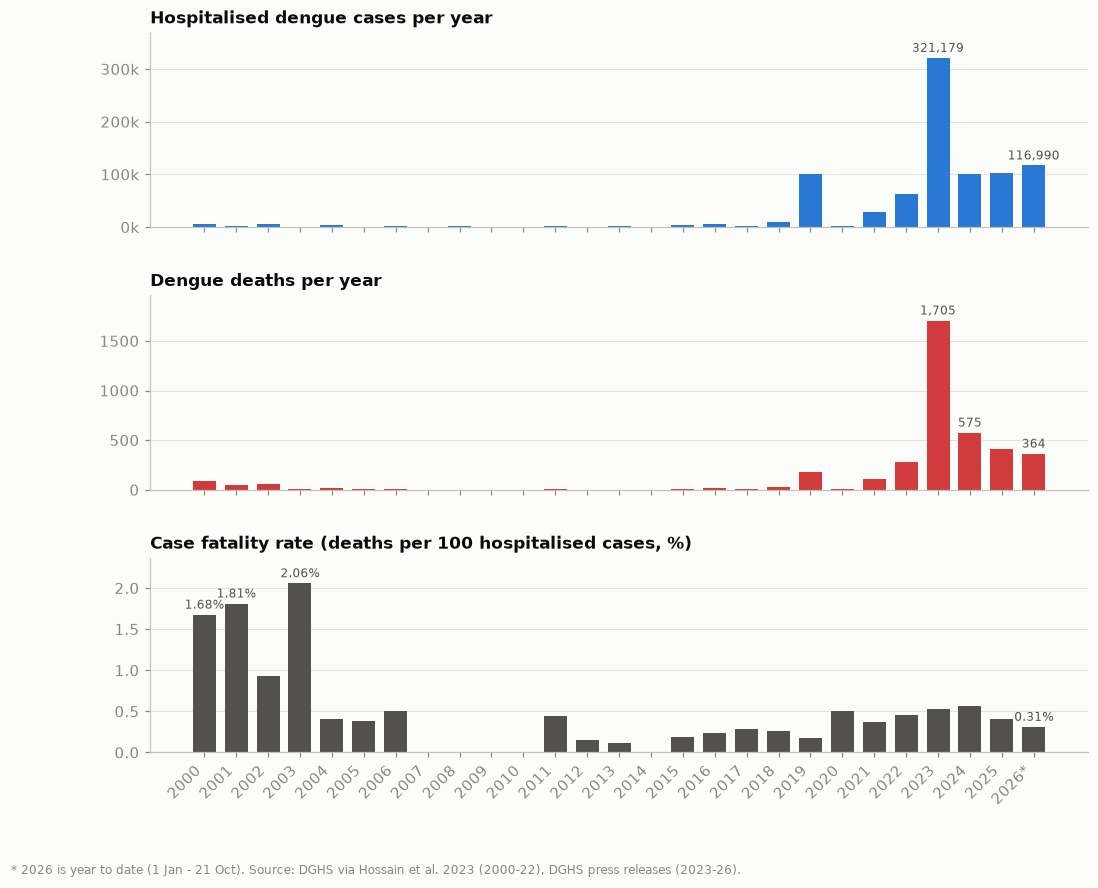

In [8]:
yn = national.copy()
labels = [f"{y}*" if p != "full year" else str(y) for y, p in zip(yn.year, yn.period)]
x = np.arange(len(yn))
fig, axes = plt.subplots(3, 1, figsize=(11, 8.5), sharex=True, gridspec_kw={"hspace": 0.35})
for ax, col, color, title, fmt, n in [
    (axes[0], "cases", BLUE, "Hospitalised dengue cases per year", "{:,.0f}", 2),
    (axes[1], "deaths", CRITICAL, "Dengue deaths per year", "{:,.0f}", 2),
    (axes[2], "cfr_pct", INK2, "Case fatality rate (deaths per 100 hospitalised cases, %)", "{:.2f}%", 3),
]:
    ax.bar(x, yn[col], color=color, width=0.72)
    ax.set_title(title)
    ax.grid(axis="x", visible=False)
    for i in sorted(set(yn[col].nlargest(n).index) | {yn.index[-1]}):
        ax.annotate(fmt.format(yn.loc[i, col]), (x[i], yn.loc[i, col]), ha="center", va="bottom",
                    fontsize=8, color=INK2, xytext=(0, 2), textcoords="offset points")
    ax.margins(y=0.15)
axes[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v/1000:.0f}k"))
axes[2].set_xticks(x, labels, rotation=45, ha="right")
note(fig, "* 2026 is year to date (1 Jan - 21 Oct). Source: DGHS via Hossain et al. 2023 (2000-22), DGHS press releases (2023-26).")
save(fig, "01_national_trend_2000_2026.png")

## 3. Seasonality — when does dengue hit?

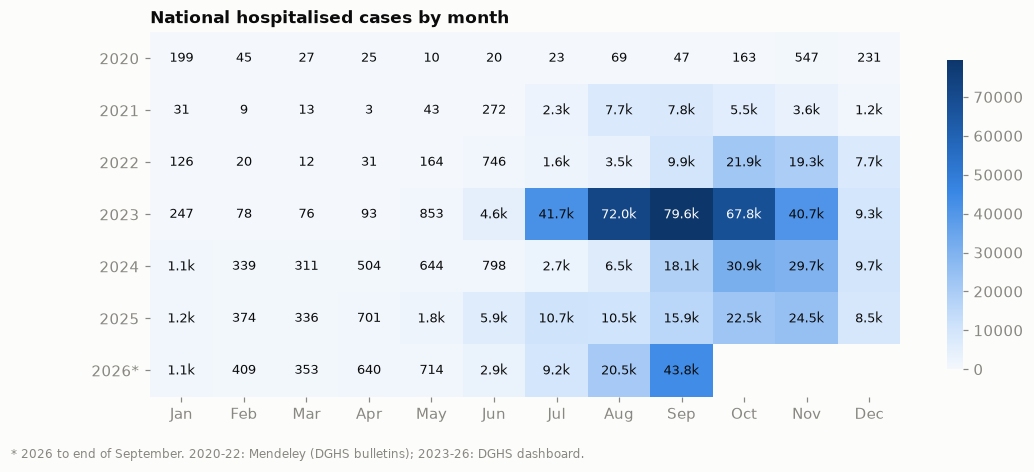

,peak_month,peak_cases,share_Jul_Nov_pct,Jun_cases
year,,,,
2020,Nov,547.0,60.4,20.0
2021,Sep,7841.0,94.4,272.0
2022,Oct,21933.0,86.4,746.0
2023,Sep,79598.0,95.2,4631.0
2024,Oct,30879.0,86.8,798.0
2025,Nov,24535.0,81.8,5949.0
2026,Sep,43774.0,92.3,2907.0


In [9]:
season = pd.concat([
    monthly_div[monthly_div.year <= 2022].groupby(["year", "month_num"], as_index=False).cases.sum(),
    nat_month,
]).pivot(index="year", columns="month_num", values="cases")
season.columns = MONTHS[: season.shape[1]]
season.to_csv(REP / "national_monthly_2020_2026.csv")


def heatmap(ax, mat, cmap, fmt, title, vmax=None):
    vmax = vmax or np.nanmax(mat.values)
    im = ax.imshow(mat.values.astype(float), cmap=cmap, aspect="auto", vmin=0, vmax=vmax)
    ax.set_xticks(range(mat.shape[1]), mat.columns)
    ax.set_yticks(range(mat.shape[0]), mat.index)
    ax.grid(False)
    for s in ax.spines.values():
        s.set_visible(False)
    for i in range(mat.shape[0]):
        for j in range(mat.shape[1]):
            v = mat.values[i, j]
            if pd.notna(v):
                ax.text(j, i, fmt(v), ha="center", va="center", fontsize=8.5,
                        color=SURFACE if v > vmax * 0.55 else INK)
    ax.set_title(title)
    return im


fig, ax = plt.subplots(figsize=(11, 4.3))
im = heatmap(ax, season.rename(index=lambda y: f"{y}*" if y == 2026 else y), CMAP_BLUE,
             lambda v: f"{v/1000:.1f}k" if v >= 1000 else f"{v:.0f}", "National hospitalised cases by month")
fig.colorbar(im, ax=ax, shrink=0.85).outline.set_visible(False)
note(fig, "* 2026 to end of September. 2020-22: Mendeley (DGHS bulletins); 2023-26: DGHS dashboard.")
save(fig, "02_seasonality_month_year.png")

share = season.loc[:, "Jul":"Nov"].sum(axis=1) / season.sum(axis=1) * 100
pd.DataFrame({"peak_month": season.idxmax(axis=1), "peak_cases": season.max(axis=1),
              "share_Jul_Nov_pct": share.round(1), "Jun_cases": season["Jun"]})

## 4. Hot zones by division, 2020 – 2026

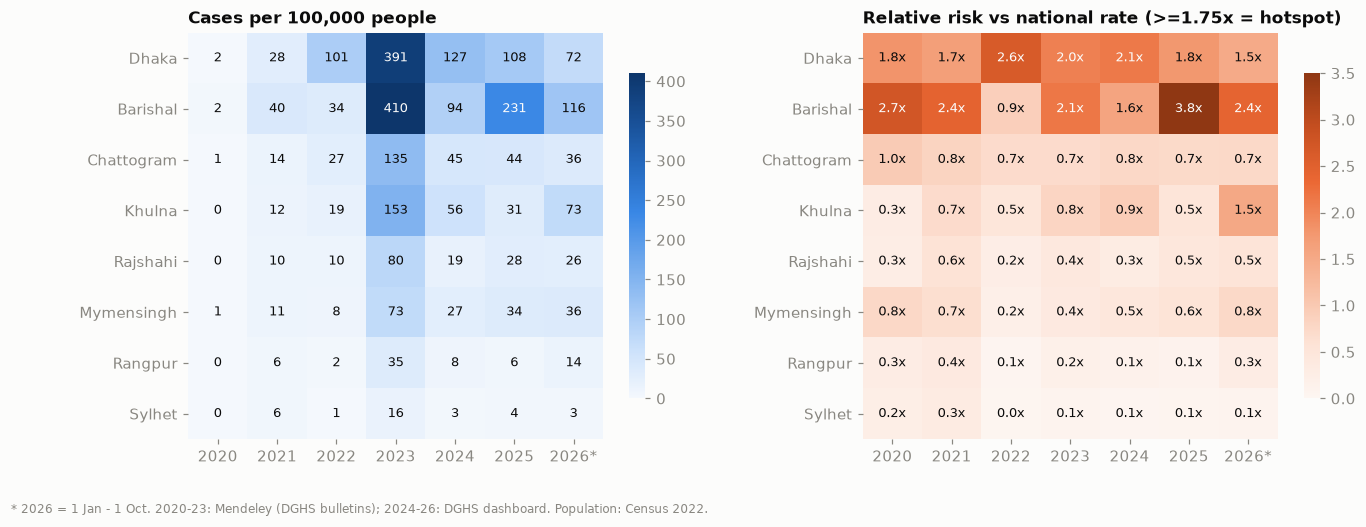

year,2020,2021,2022,2023,2024,2025,2026
division,,,,,,,
Dhaka,hotspot,elevated,hotspot,hotspot,hotspot,hotspot,elevated
Barishal,hotspot,hotspot,average,hotspot,elevated,hotspot,hotspot
Chattogram,average,average,low,low,average,low,low
Khulna,low,low,low,average,average,low,elevated
Rajshahi,low,low,low,low,low,low,low
Mymensingh,average,low,low,low,low,low,low
Rangpur,low,low,low,low,low,low,low
Sylhet,low,low,low,low,low,low,low


In [10]:
inc = div_year.pivot(index="division", columns="year", values="incidence_per_100k").loc[DIVISIONS].rename(columns=YEAR_LABEL)
rr = div_year.pivot(index="division", columns="year", values="relative_risk").loc[DIVISIONS].rename(columns=YEAR_LABEL)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), gridspec_kw={"wspace": 0.3})
im = heatmap(axes[0], inc, CMAP_BLUE, lambda v: f"{v:,.0f}", "Cases per 100,000 people")
fig.colorbar(im, ax=axes[0], shrink=0.8).outline.set_visible(False)
im = heatmap(axes[1], rr, CMAP_ORANGE, lambda v: f"{v:.1f}x", "Relative risk vs national rate (>=1.75x = hotspot)", vmax=3.5)
fig.colorbar(im, ax=axes[1], shrink=0.8).outline.set_visible(False)
note(fig, "* 2026 = 1 Jan - 1 Oct. 2020-23: Mendeley (DGHS bulletins); 2024-26: DGHS dashboard. Population: Census 2022.", -0.03)
save(fig, "03_hotspot_heatmap_division_year.png")
div_year.pivot(index="division", columns="year", values="hotspot_tier").loc[DIVISIONS]

## 5. Maps — 2025 vs 2026
Same colour scale on both maps so the years can be compared directly. Labels show cases per 100,000 and the raw case count.

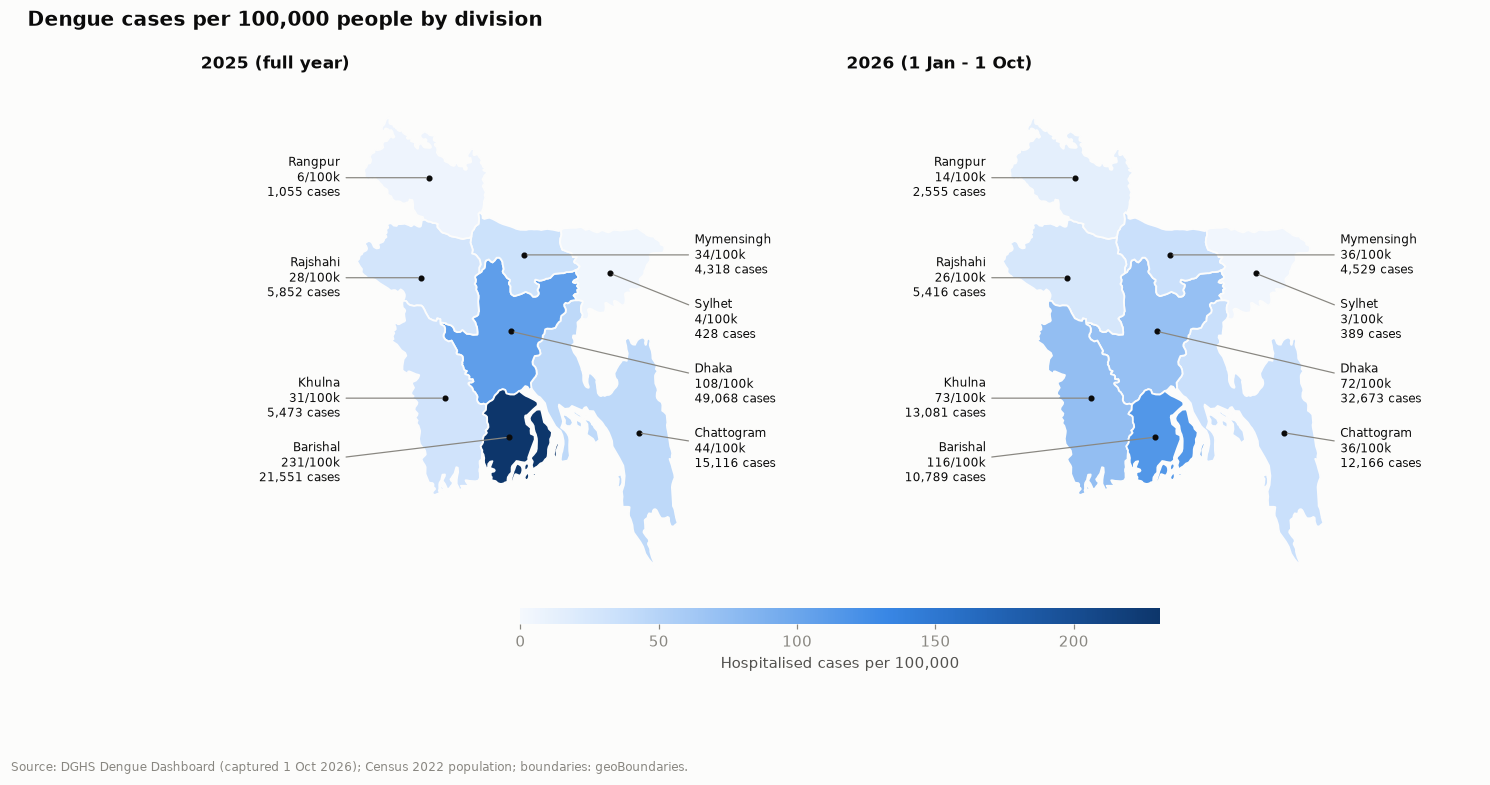

In [11]:
GB_DIV = {"Barisal": "Barishal", "Chittagong": "Chattogram", "Rajshani": "Rajshahi"}
adm1 = gpd.read_file(RAW / "boundaries/bgd_ADM1.geojson").to_crs(32646)
adm1["division"] = adm1.shapeName.replace(GB_DIV)
adm2 = gpd.read_file(RAW / "boundaries/bgd_ADM2.geojson").to_crs(32646)
assert set(adm1.division) == set(DIVISIONS)


def leader_labels(ax, items, side="left", gap=38_000, margin=True):
    # Place labels in a column beside the map with thin leader lines, so clustered districts don't collide.
    # items: list of (text, point) in map coordinates (metres, UTM 46N).
    minx, miny, maxx, maxy = adm1.total_bounds
    x_text = minx - 25_000 if side == "left" else maxx + 25_000
    last_y = np.inf
    for text, p in sorted(items, key=lambda t: -t[1].y):
        y = min(p.y, last_y - gap)
        last_y = y
        ax.plot(p.x, p.y, "o", ms=3, color=INK)
        ax.annotate(text, xy=(p.x, p.y), xytext=(x_text, y), ha="right" if side == "left" else "left",
                    va="center", fontsize=8, color=INK,
                    arrowprops=dict(arrowstyle="-", color=MUTED, lw=0.8, shrinkA=2, shrinkB=2))
    if margin:
        pad = 260_000
        ax.set_xlim(minx - pad if side == "left" else minx - 10_000, maxx + 10_000 if side == "left" else maxx + pad)


def division_map(ax, year, col, cmap, vmax, fmt, title):
    g = adm1.merge(div_year[div_year.year == year], on="division")
    g.plot(column=col, cmap=cmap, vmin=0, vmax=vmax, ax=ax, edgecolor=SURFACE, linewidth=1.2)
    west = {"Rangpur", "Rajshahi", "Khulna", "Barishal"}
    for side in ("left", "right"):
        leader_labels(ax, [(f"{r.division}\n{fmt(r)}", r.geometry.representative_point())
                           for _, r in g.iterrows() if (r.division in west) == (side == "left")],
                      side=side, gap=95_000, margin=False)
    minx, _, maxx, _ = adm1.total_bounds
    ax.set_xlim(minx - 230_000, maxx + 230_000)
    ax.set_title(title)
    ax.set_axis_off()


def map_pair(col, cmap, fmt, title, cbar_label, fname):
    vmax = div_year.loc[div_year.year.isin([2025, 2026]), col].max()
    fig, axes = plt.subplots(1, 2, figsize=(15, 7.2), gridspec_kw={"wspace": 0.02})
    division_map(axes[0], 2025, col, cmap, vmax, fmt, f"2025 (full year)")
    division_map(axes[1], 2026, col, cmap, vmax, fmt, f"2026 (1 Jan - 1 Oct)")
    sm = plt.cm.ScalarMappable(cmap=cmap, norm=plt.Normalize(0, vmax))
    cb = fig.colorbar(sm, ax=axes, shrink=0.5, location="bottom", pad=0.02, aspect=40)
    cb.set_label(cbar_label, color=INK2)
    cb.outline.set_visible(False)
    fig.suptitle(title, x=0.02, ha="left", fontweight="bold", fontsize=13)
    note(fig, "Source: DGHS Dengue Dashboard (captured 1 Oct 2026); Census 2022 population; boundaries: geoBoundaries.", 0.02)
    save(fig, fname)


map_pair("incidence_per_100k", CMAP_BLUE, lambda r: f"{r.incidence_per_100k:.0f}/100k\n{r.cases:,} cases",
         "Dengue cases per 100,000 people by division", "Hospitalised cases per 100,000", "04_map_cases_2025_vs_2026.png")

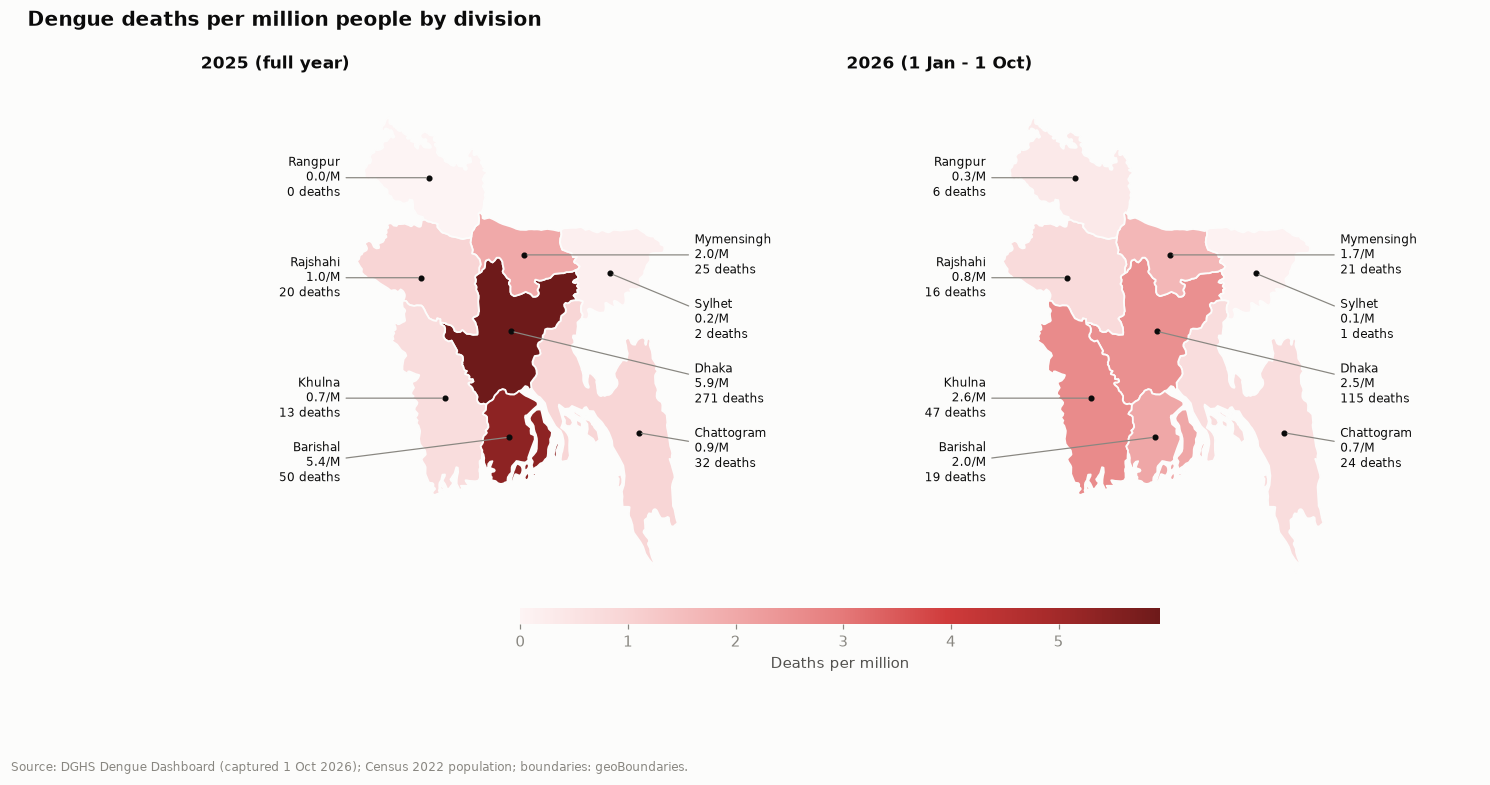

In [12]:
map_pair("deaths_per_million", CMAP_RED, lambda r: f"{r.deaths_per_million:.1f}/M\n{r.deaths} deaths",
         "Dengue deaths per million people by division", "Deaths per million", "05_map_deaths_2025_vs_2026.png")

In [13]:
cmp = div_year[div_year.year.isin([2025, 2026])].pivot(index="division", columns="year",
                                                       values=["cases", "deaths", "incidence_per_100k"]).loc[DIVISIONS]
cmp[("change", "cases_2026_vs_2025_pct")] = (cmp[("cases", 2026)] / cmp[("cases", 2025)] * 100 - 100).round(0)
cmp

cases          deaths        incidence_per_100k                        change
year           2025     2026   2025   2026               2025   2026 cases_2026_vs_2025_pct
division                                                                                   
Dhaka       49068.0  32673.0  271.0  115.0              107.5   71.6                  -33.0
Barishal    21551.0  10789.0   50.0   19.0              231.1  115.7                  -50.0
Chattogram  15116.0  12166.0   32.0   24.0               44.2   35.6                  -20.0
Khulna       5473.0  13081.0   13.0   47.0               30.7   73.4                  139.0
Rajshahi     5852.0   5416.0   20.0   16.0               28.1   26.0                   -7.0
Mymensingh   4318.0   4529.0   25.0   21.0               34.2   35.8                    5.0
Rangpur      1055.0   2555.0    0.0    6.0                5.9   14.2                  142.0
Sylhet        428.0    389.0    2.0    1.0                3.7    3.4                   -9.0

### Dhaka city vs the rest of Dhaka division
The dashboard splits Dhaka into the two city corporations (DNCC, DSCC) and the rest of the division.

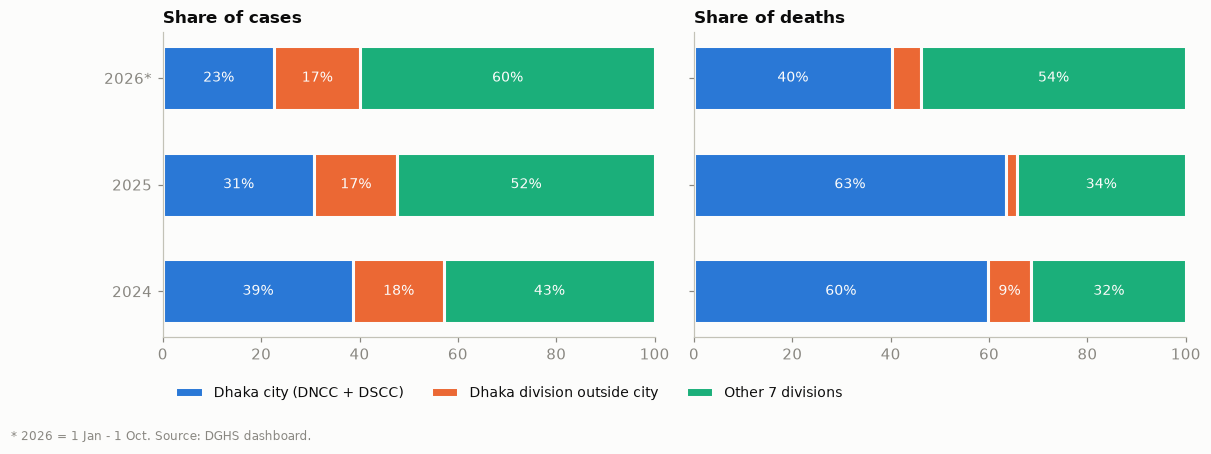

cases  deaths  cases_share_pct  deaths_share_pct  cfr_pct
year zone                                                                                  
2024 Dhaka city (DNCC + DSCC)     39133     343             38.7              59.7     0.88
     Dhaka division outside city  18744      51             18.5               8.9     0.27
     Other 7 divisions            43334     181             42.8              31.5     0.42
2025 Dhaka city (DNCC + DSCC)     31682     262             30.8              63.4     0.83
     Dhaka division outside city  17386       9             16.9               2.2     0.05
     Other 7 divisions            53793     142             52.3              34.4     0.26
2026 Dhaka city (DNCC + DSCC)     18510     100             22.7              40.2     0.54
     Dhaka division outside city  14163      15             17.4               6.0     0.11
     Other 7 divisions            48925     134             60.0              53.8     0.27

In [14]:
area = dash_area.copy()
area["zone"] = np.select([area.area.isin(["DNCC", "DSCC"]), area.division == "Dhaka"],
                         ["Dhaka city (DNCC + DSCC)", "Dhaka division outside city"], "Other 7 divisions")
zone = area.groupby(["year", "zone"])[["cases", "deaths"]].sum()
zone_share = (zone / zone.groupby("year").transform("sum") * 100).round(1).add_suffix("_share_pct")
zone_tbl = zone.join(zone_share).assign(cfr_pct=lambda t: (t.deaths / t.cases * 100).round(2))
zone_tbl.to_csv(REP / "dhaka_city_vs_rest_2024_2026.csv")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), sharey=True, gridspec_kw={"wspace": 0.08})
zones = ["Dhaka city (DNCC + DSCC)", "Dhaka division outside city", "Other 7 divisions"]
colors = [BLUE, ORANGE, "#1baf7a"]
for ax, col, title in [(axes[0], "cases_share_pct", "Share of cases"), (axes[1], "deaths_share_pct", "Share of deaths")]:
    t = zone_tbl[col].unstack()[zones].rename(index=YEAR_LABEL)
    left = np.zeros(len(t))
    for z, c in zip(zones, colors):
        ax.barh(t.index.astype(str), t[z], left=left, color=c, height=0.6, edgecolor=SURFACE, linewidth=2, label=z)
        for i, (l, v) in enumerate(zip(left, t[z])):
            if v >= 8:
                ax.text(l + v / 2, i, f"{v:.0f}%", ha="center", va="center", fontsize=9, color=SURFACE)
        left += t[z].values
    ax.set_xlim(0, 100)
    ax.set_title(title)
    ax.grid(False)
    ax.invert_yaxis()
axes[0].legend(ncol=3, loc="upper left", bbox_to_anchor=(0, -0.12), frameon=False, fontsize=9)
note(fig, "* 2026 = 1 Jan - 1 Oct. Source: DGHS dashboard.", -0.15)
save(fig, "06_dhaka_city_vs_rest.png")
zone_tbl

## 6. District-level hot zones (2016 – 2023)
The latest open district-level series ends in early 2024, so district maps show 2022 and 2023 (the record year). Each map has its own scale because 2023 was ~5x larger than 2022.

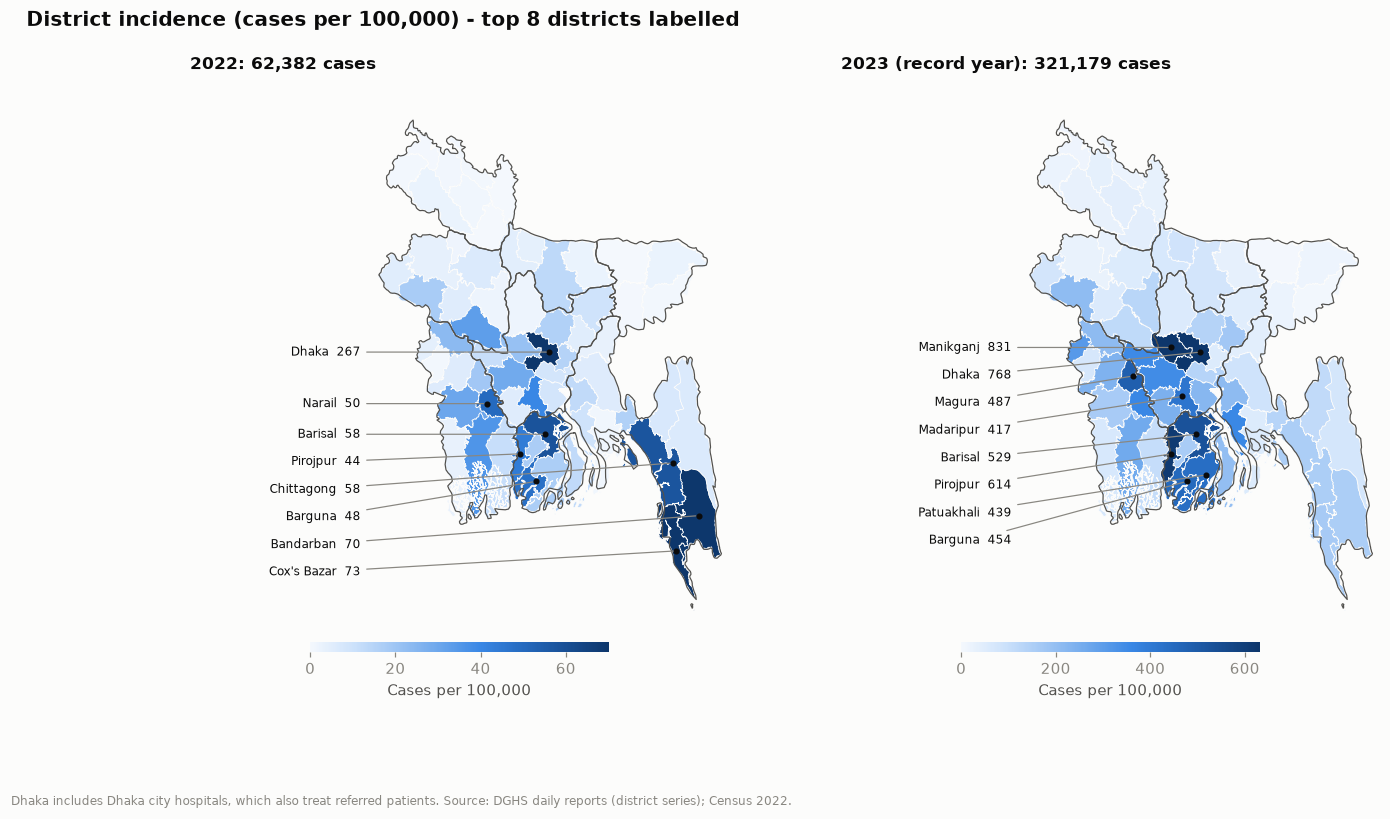

In [15]:
def district_map(ax, year, title):
    g = adm2.merge(district_year[district_year.year == year], left_on="shapeName", right_on="district", how="left")
    vmax = g.incidence_per_100k.quantile(0.97)
    g.plot(column="incidence_per_100k", cmap=CMAP_BLUE, vmin=0, vmax=vmax, ax=ax, edgecolor=SURFACE, linewidth=0.5)
    adm1.boundary.plot(ax=ax, color=INK2, linewidth=0.8)
    leader_labels(ax, [(f"{r.shapeName}  {r.incidence_per_100k:.0f}", r.geometry.representative_point())
                       for _, r in g.nlargest(8, "incidence_per_100k").iterrows()])
    sm = plt.cm.ScalarMappable(cmap=CMAP_BLUE, norm=plt.Normalize(0, vmax))
    cb = plt.colorbar(sm, ax=ax, shrink=0.55, location="bottom", pad=0.01, aspect=30)
    cb.set_label("Cases per 100,000", color=INK2)
    cb.outline.set_visible(False)
    ax.set_title(title)
    ax.set_axis_off()


fig, axes = plt.subplots(1, 2, figsize=(14, 7.6))
district_map(axes[0], 2022, "2022: 62,382 cases")
district_map(axes[1], 2023, "2023 (record year): 321,179 cases")
fig.suptitle("District incidence (cases per 100,000) - top 8 districts labelled", x=0.02, ha="left", fontweight="bold", fontsize=13)
note(fig, "Dhaka includes Dhaka city hospitals, which also treat referred patients. Source: DGHS daily reports (district series); Census 2022.", 0.03)
save(fig, "07_map_districts_2022_2023.png")

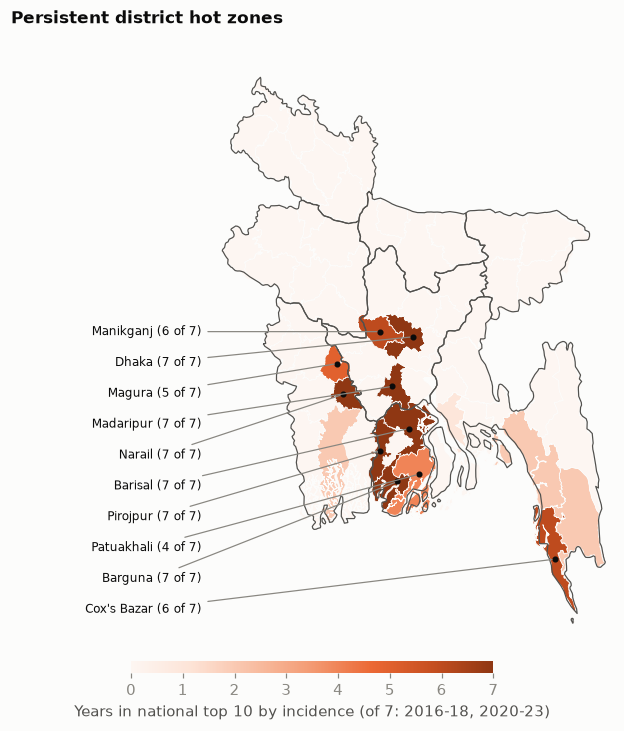

,years_in_top10,division,avg_incidence
district,,,
Dhaka,7,Dhaka,172.1
Pirojpur,7,Barishal,101.9
Barisal,7,Barishal,91.7
Barguna,7,Barishal,78.4
Madaripur,7,Dhaka,71.2
Narail,7,Khulna,64.8
Manikganj,6,Dhaka,131.3
Cox's Bazar,6,Chattogram,43.1
Magura,5,Khulna,78.3


In [16]:
# Persistence: in how many years (2016-2023, excl. 2019) was each district in the national top 10 by incidence?
district_year["rank"] = district_year.groupby("year").incidence_per_100k.rank(ascending=False)
persist = (district_year.assign(top10=district_year["rank"] <= 10).groupby("district")
           .agg(years_in_top10=("top10", "sum"), division=("division", "first"),
                avg_incidence=("incidence_per_100k", "mean")))
n_years = district_year.year.nunique()

g = adm2.merge(persist, left_on="shapeName", right_index=True, how="left")
fig, ax = plt.subplots(figsize=(8.5, 8.5))
g.plot(column="years_in_top10", cmap=CMAP_ORANGE, vmin=0, vmax=n_years, ax=ax, edgecolor=SURFACE, linewidth=0.5)
adm1.boundary.plot(ax=ax, color=INK2, linewidth=0.8)
leader_labels(ax, [(f"{r.shapeName} ({r.years_in_top10:.0f} of {n_years})", r.geometry.representative_point())
                  for _, r in g[g.years_in_top10 >= 4].iterrows()])
sm = plt.cm.ScalarMappable(cmap=CMAP_ORANGE, norm=plt.Normalize(0, n_years))
cb = fig.colorbar(sm, ax=ax, shrink=0.5, location="bottom", pad=0.01, aspect=30)
cb.set_label(f"Years in national top 10 by incidence (of {n_years}: 2016-18, 2020-23)", color=INK2)
cb.outline.set_visible(False)
ax.set_title("Persistent district hot zones")
ax.set_axis_off()
save(fig, "08_map_district_persistence.png")

persist.sort_values(["years_in_top10", "avg_incidence"], ascending=False).head(15).round(1)

In [17]:
top = (district_year[district_year.year == 2023].nlargest(15, "incidence_per_100k")
       [["district", "division", "cases", "incidence_per_100k"]].round(1).reset_index(drop=True))
top.index += 1
district_year.to_csv(REP / "district_year_burden_2016_2023.csv", index=False)
top

,district,division,cases,incidence_per_100k
1,Manikganj,Dhaka,12952,831.3
2,Dhaka,Dhaka,113233,768.5
3,Pirojpur,Barishal,7361,614.3
4,Barisal,Barishal,13603,529.2
5,Magura,Khulna,5031,487.0
6,Barguna,Barishal,4592,454.4
7,Patuakhali,Barishal,7579,438.8
8,Madaripur,Dhaka,5386,416.5
9,Narail,Khulna,2841,360.2
10,Lakshmipur,Chattogram,6950,358.6


## 7. The 2026 season so far vs 2025 (weekly, by division)

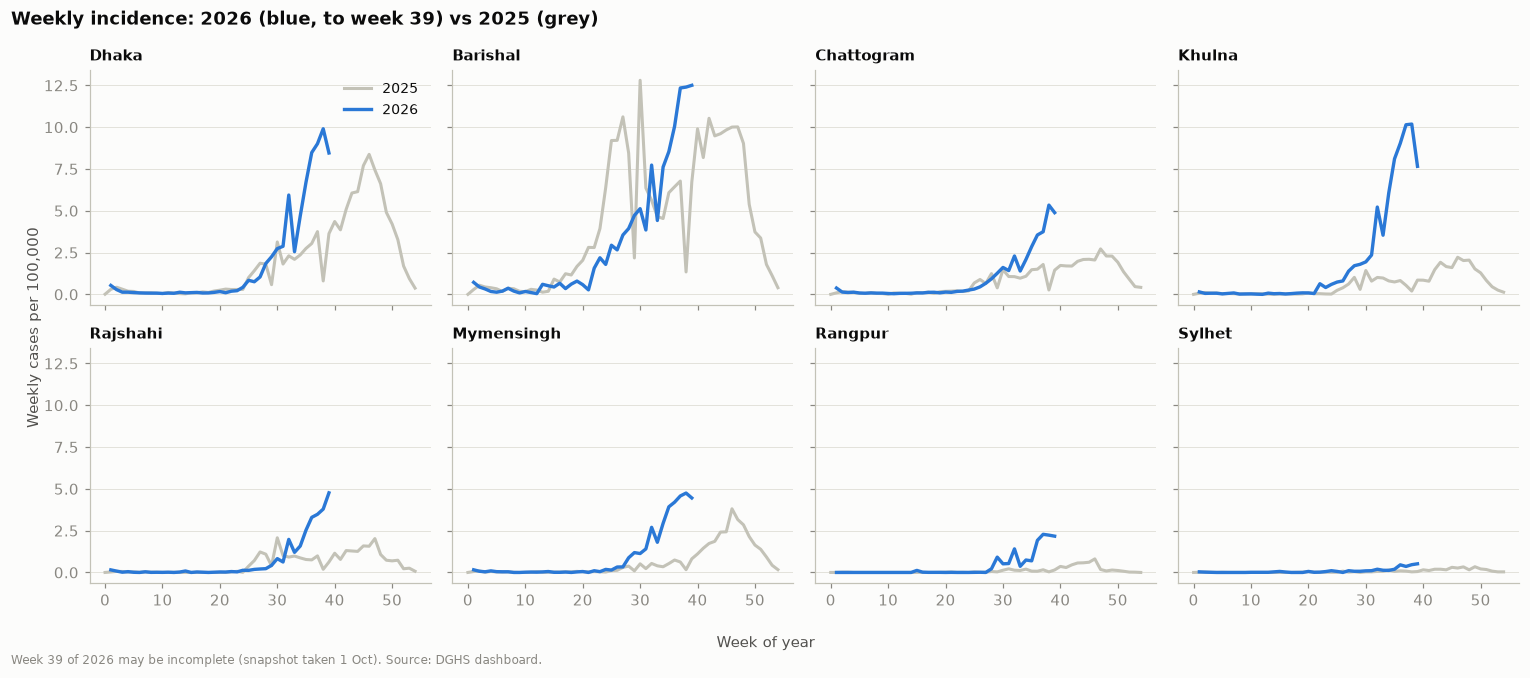

Cases in weeks 1-39, 2026 vs same weeks of 2025


year,2025,2026,change_pct
division,,,
Dhaka,16647,32668,96.0
Barishal,12005,10786,-10.0
Chattogram,6335,12165,92.0
Khulna,2079,13081,529.0
Rajshahi,2788,5416,94.0
Mymensingh,843,4529,437.0
Rangpur,278,2555,819.0
Sylhet,114,389,241.0


In [18]:
w = weekly[weekly.year.isin([2025, 2026])].copy()
w["inc"] = w.cases / w.division.map(div_pop) * 1e5
fig, axes = plt.subplots(2, 4, figsize=(14, 6), sharex=True, sharey=True)
for ax, div in zip(axes.flat, DIVISIONS):
    for y, c, lw in [(2025, AXIS, 2), (2026, BLUE, 2.2)]:
        s = w[(w.division == div) & (w.year == y)]
        ax.plot(s.week, s.inc, color=c, linewidth=lw, label=str(y))
    ax.set_title(div, fontsize=10)
    ax.grid(axis="x", visible=False)
axes[0, 0].legend(frameon=False, fontsize=9)
fig.supylabel("Weekly cases per 100,000", color=INK2, fontsize=10)
fig.supxlabel("Week of year", color=INK2, fontsize=10)
fig.suptitle("Weekly incidence: 2026 (blue, to week 39) vs 2025 (grey)", x=0.01, ha="left", fontweight="bold")
note(fig, "Week 39 of 2026 may be incomplete (snapshot taken 1 Oct). Source: DGHS dashboard.", -0.01)
fig.tight_layout()
save(fig, "09_weekly_2026_vs_2025.png")

cum = (w[w.week <= w.loc[w.year == 2026, "week"].max()].groupby(["division", "year"]).cases.sum().unstack())
cum["change_pct"] = (cum[2026] / cum[2025] * 100 - 100).round(0)
print("Cases in weeks 1-39, 2026 vs same weeks of 2025")
cum.loc[DIVISIONS]

## 8. Deaths: where, and how deadly

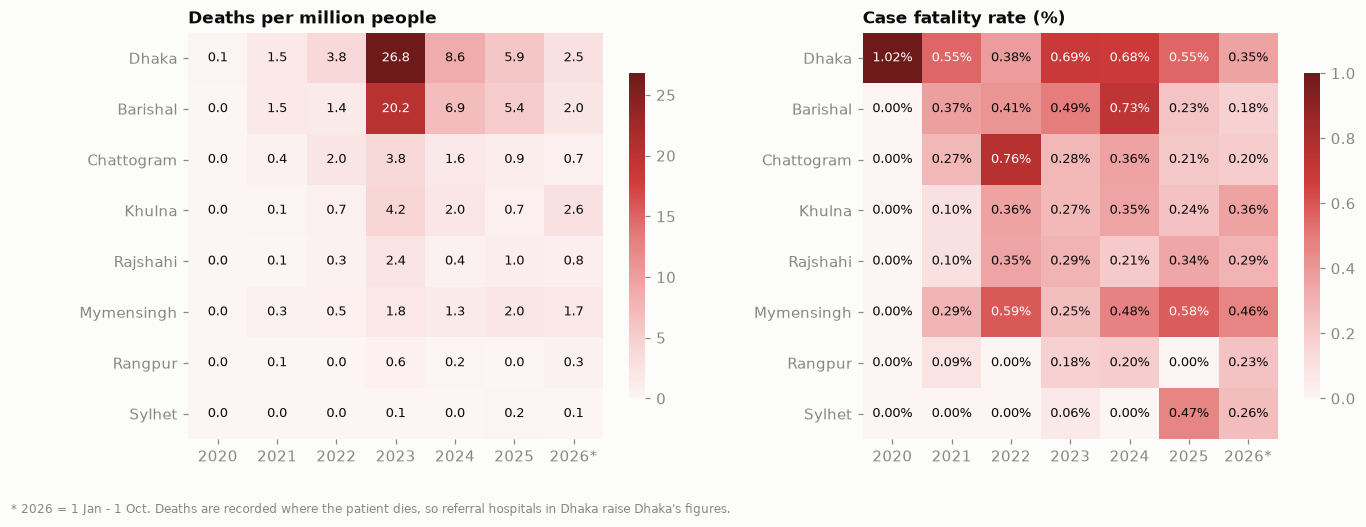

In [19]:
dpm = div_year.pivot(index="division", columns="year", values="deaths_per_million").loc[DIVISIONS].rename(columns=YEAR_LABEL)
cfr = div_year.pivot(index="division", columns="year", values="cfr_pct").loc[DIVISIONS].rename(columns=YEAR_LABEL)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), gridspec_kw={"wspace": 0.3})
im = heatmap(axes[0], dpm, CMAP_RED, lambda v: f"{v:.1f}", "Deaths per million people")
fig.colorbar(im, ax=axes[0], shrink=0.8).outline.set_visible(False)
im = heatmap(axes[1], cfr, CMAP_RED, lambda v: f"{v:.2f}%", "Case fatality rate (%)", vmax=1.0)
fig.colorbar(im, ax=axes[1], shrink=0.8).outline.set_visible(False)
note(fig, "* 2026 = 1 Jan - 1 Oct. Deaths are recorded where the patient dies, so referral hospitals in Dhaka raise Dhaka's figures.", -0.03)
save(fig, "10_deaths_cfr_division_year.png")

### Age and sex
Some age labels in the dashboard were mangled by a spreadsheet (e.g. `06-Oct` = 6–10, `Nov-15` = 11–15); these are repaired, and a handful of junk labels with tiny counts are dropped.

In [20]:
AGE_FIX = {"06-Oct": "06-10", "6-10": "06-10", "Nov-15": "11-15", ">80": "80+"}
AGE_ORDER = ["0-5", "06-10", "11-15", "16-20", "21-25", "26-30", "31-35", "36-40", "41-45", "46-50",
             "51-55", "56-60", "61-65", "66-70", "71-75", "76-80", "80+"]


def age_sex(year, key):
    ch = DASH[year][key]
    rows = [{"age": AGE_FIX.get(str(a).strip(), str(a).strip()), "sex": s["name"], "n": abs(v)}
            for s in ch["series"] for a, v in zip(ch["categories"], s["data"])]
    t = pd.DataFrame(rows)
    return t[t.age.isin(AGE_ORDER)].groupby(["age", "sex"]).n.sum().unstack().reindex(AGE_ORDER).fillna(0)


sex_rows = []
for y in (2023, 2024, 2025, 2026):
    c, dth = age_sex(y, "dengue_affected_by_age_group"), age_sex(y, "dengue_death_by_age_group")
    for sex in ("Male", "Female"):
        sex_rows.append({"year": y, "sex": sex, "cases": int(c[sex].sum()), "deaths": int(dth[sex].sum()),
                         "cfr_pct": round(dth[sex].sum() / c[sex].sum() * 100, 2)})
sex_tbl = pd.DataFrame(sex_rows)
sex_tbl.to_csv(REP / "cfr_by_sex_2023_2026.csv", index=False)
sex_tbl.pivot(index="year", columns="sex", values=["cases", "deaths", "cfr_pct"])

cases           deaths        cfr_pct      
sex     Female      Male Female   Male  Female  Male
year                                                
2023  127297.0  189705.0  970.0  735.0    0.76  0.39
2024   37326.0   63885.0  294.0  281.0    0.79  0.44
2025   38513.0   64202.0  197.0  215.0    0.51  0.33
2026   30671.0   50677.0  128.0  115.0    0.42  0.23

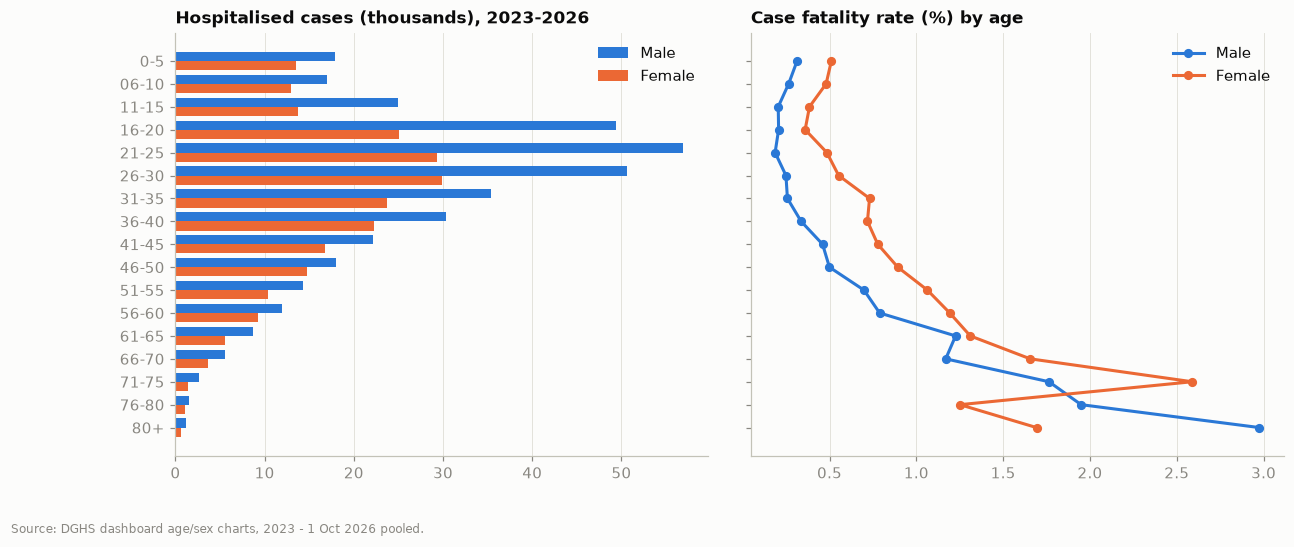

,cases,deaths,cfr_male,cfr_female
age,,,,
0-5,31410,125.0,0.31,0.51
06-10,29942,107.0,0.26,0.48
11-15,38743,104.0,0.20,0.38
16-20,74446,192.0,0.21,0.36
21-25,86199,248.0,0.19,0.48
26-30,80524,291.0,0.25,0.55
31-35,59055,264.0,0.26,0.73
36-40,52626,262.0,0.34,0.72
41-45,38906,232.0,0.46,0.78


In [21]:
# Pool 2023-2026 for stable age-specific numbers
cases_age = sum(age_sex(y, "dengue_affected_by_age_group") for y in (2023, 2024, 2025, 2026))
deaths_age = sum(age_sex(y, "dengue_death_by_age_group") for y in (2023, 2024, 2025, 2026))
cfr_age = (deaths_age / cases_age * 100)

fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True, gridspec_kw={"wspace": 0.08})
y = np.arange(len(AGE_ORDER))
axes[0].barh(y - 0.2, cases_age["Male"] / 1000, height=0.4, color=BLUE, label="Male")
axes[0].barh(y + 0.2, cases_age["Female"] / 1000, height=0.4, color=ORANGE, label="Female")
axes[0].set_title("Hospitalised cases (thousands), 2023-2026")
axes[1].plot(cfr_age["Male"], y, color=BLUE, marker="o", markersize=5, linewidth=2, label="Male")
axes[1].plot(cfr_age["Female"], y, color=ORANGE, marker="o", markersize=5, linewidth=2, label="Female")
axes[1].set_title("Case fatality rate (%) by age")
axes[0].set_yticks(y, AGE_ORDER)
axes[0].invert_yaxis()
for ax in axes:
    ax.legend(frameon=False)
    ax.grid(axis="y", visible=False)
note(fig, "Source: DGHS dashboard age/sex charts, 2023 - 1 Oct 2026 pooled.", -0.03)
save(fig, "11_age_sex.png")
pd.DataFrame({"cases": cases_age.sum(axis=1), "deaths": deaths_age.sum(axis=1),
              "cfr_male": cfr_age["Male"].round(2), "cfr_female": cfr_age["Female"].round(2)})

## 9. Climate: temperature and humidity vs cases
Spearman correlation between a division's monthly cases and its temperature / humidity *N* months earlier (Mendeley data, 2020–2025). Descriptive only — the annual cycle drives both, so this is not a causal estimate.

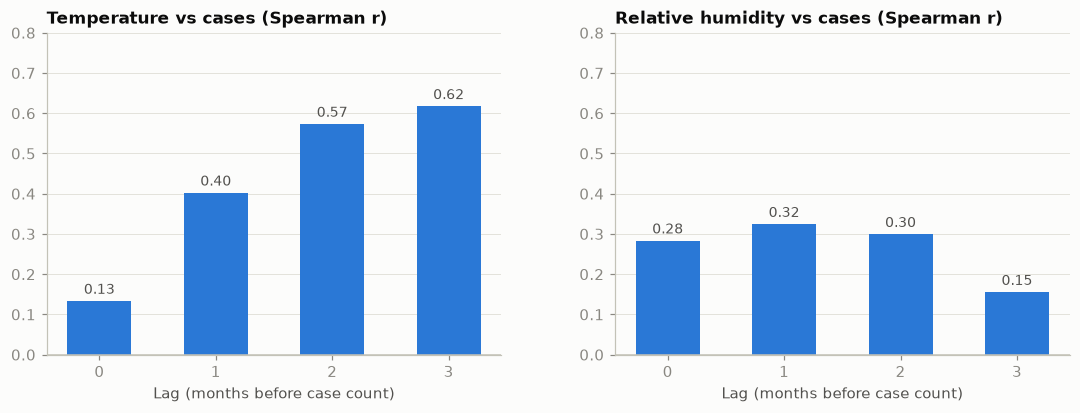

variable,humidity,temperature_c
lag_months,,
0,0.283,0.133
1,0.324,0.402
2,0.299,0.573
3,0.155,0.617


In [22]:
rows = []
for var in ["temperature_c", "humidity"]:
    for lag in range(4):
        dd = monthly_div.sort_values("date").copy()
        dd["x"] = dd.groupby("division")[var].shift(lag)
        dd = dd.dropna(subset=["x"])
        rows.append({"variable": var, "lag_months": lag, "n": len(dd),
                     "spearman_r": round(dd.cases.rank().corr(dd.x.rank()), 3)})  # Spearman = Pearson on ranks
lags = pd.DataFrame(rows)
lags.to_csv(REP / "climate_lag_correlations.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), gridspec_kw={"wspace": 0.25})
for ax, var, title in [(axes[0], "temperature_c", "Temperature"), (axes[1], "humidity", "Relative humidity")]:
    t = lags[lags.variable == var]
    ax.bar(t.lag_months.astype(str), t.spearman_r, color=BLUE, width=0.55)
    for i, v in enumerate(t.spearman_r):
        ax.text(i, v + 0.01, f"{v:.2f}", ha="center", va="bottom", fontsize=9, color=INK2)
    ax.axhline(0, color=AXIS, linewidth=1)
    ax.set_ylim(0, 0.8)
    ax.set_xlabel("Lag (months before case count)")
    ax.set_title(f"{title} vs cases (Spearman r)")
    ax.grid(axis="x", visible=False)
save(fig, "12_climate_lag_correlation.png")
lags.pivot(index="lag_months", columns="variable", values="spearman_r")

## 10. Key findings

**Scale**
- Dengue went from an occasional outbreak (about 50,000 cases in total over 2000–2018) to a yearly epidemic: there have been more than 100,000 hospitalised cases every year since 2023. 2023 was the worst year on record, with 321,179 cases and 1,705 deaths.
- **2026 is running ahead of 2025.** By 21 Oct 2026 there were 116,990 cases and 364 deaths, more than in all of 2025 (102,861). For weeks 1–39, 2026 had **81,589 cases against 41,089** in the same weeks of 2025, about twice as many. September 2026 (43,774 cases) was the busiest month since 2023.

**Hot zones (maps in section 5, districts in section 6)**
- **Barishal is the most affected division for its population**: 231 cases per 100k people in 2025 (3.8× the national rate) and 116 per 100k in 2026 so far (2.4×). It has been a hotspot in 6 of the last 7 years.
- **Dhaka division** was a hotspot in 2025 (108 per 100k, 1.8×) and is "elevated" in 2026 (1.5×).
- **Khulna is the new hot zone in 2026.** Its cases rose from 31 to 73 per 100k (5,473 to 13,081, with October–December still to come), it moved from 0.5× to 1.5× the national rate, and it now has the **highest death rate in the country, 2.6 deaths per million** (47 deaths).
- **Northern divisions are growing from a low base.** Comparing the same weeks of 2025, cases are up 8× in Rangpur and 5× in Mymensingh.
- **Persistent district hot zones (2016–2023):** Dhaka, Barisal, Pirojpur, Barguna, Madaripur and Narail were in the national top 10 by incidence in **all 7 years**, and Manikganj and Cox's Bazar in 6. In the record year 2023, Manikganj (831 per 100k), Dhaka (768) and Pirojpur (614) had the highest incidence.
- **Sylhet** has stayed low in every year (at most 0.3× the national rate).

**Deaths**
- The national case fatality rate (CFR) peaked at 0.57% in 2024, fell to 0.40% in 2025, and is 0.31% in 2026 so far.
- **Deaths are concentrated in Dhaka city.** The two Dhaka city corporations recorded 31% of cases but 63% of deaths in 2025, with a CFR of about 0.85%, compared with 0.05–0.4% elsewhere. Severe patients are referred to Dhaka hospitals and their deaths are recorded there. In 2026 the city's share of deaths has fallen to 40% as deaths increase outside Dhaka.
- **Women are about twice as likely as men to die once hospitalised**, and this holds in every year: CFR 0.76% vs 0.39% in 2023 and 0.42% vs 0.23% in 2026. This is despite men making up about 60–63% of admissions.
- **Risk rises steeply with age.** Most cases are aged 16–35, but CFR goes from 0.2–0.5% under 30 to more than 1% over 55.

**Season and climate**
- 82–95% of each year's cases occur from **July to November**, with the peak in September, October or November.
- Cases follow temperature with a **2–3 month lag** (Spearman r ≈ 0.6) and humidity with a 1-month lag (r ≈ 0.3). This is consistent with the monsoon breeding cycle, but it is a correlation, not a forecast model.

**Data caveats:** "cases" means hospitalised, reported cases. Deaths are recorded where the patient dies. The 2026 division figures run to 1 Oct (the national totals to 21 Oct). The open district series ends in early 2024, and its 2019 data is incomplete. Population figures are fixed at Census 2022.